<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/hough2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

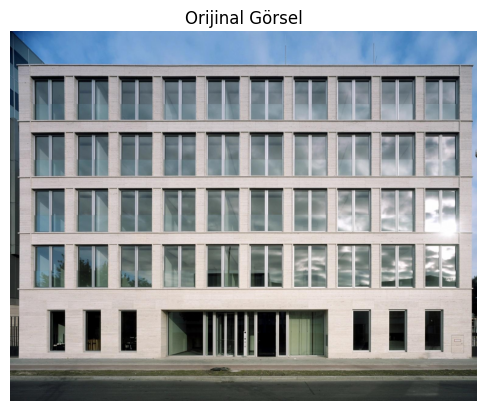

In [2]:
resim = cv2.imread("image09.jpeg")

if resim is None:
    raise FileNotFoundError("Görsel bulunamadı. Dosya yolunu kontrol et.")

plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")
plt.show()

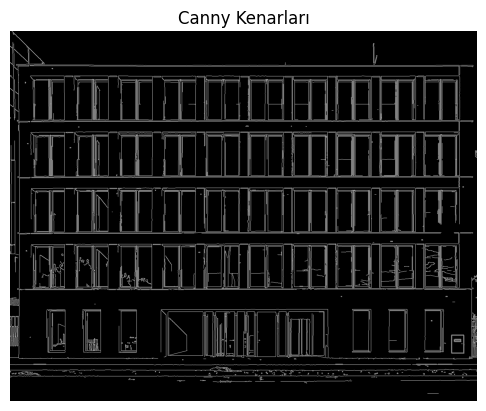

In [3]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

kenarlar = cv2.Canny(gri, 100, 200)

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()

In [5]:
yukseklik, genislik = kenarlar.shape

max_rho = int(np.ceil(np.sqrt(genislik**2 + yukseklik**2)))

acilar = np.deg2rad(np.arange(-90, 90))

sin_tablosu = np.sin(acilar)
cos_tablosu = np.cos(acilar)

oylama = np.zeros(
    (2 * max_rho + 1, len(acilar)),
    dtype=np.int32
)

print("Oylama matrisi boyutu:", oylama.shape)

Oylama matrisi boyutu: (3921, 180)


In [6]:
ys, xs = np.where(kenarlar > 0)

for t in range(len(acilar)):

    rho = xs * cos_tablosu[t] + ys * sin_tablosu[t]

    rho_indeks = np.rint(rho).astype(int) + max_rho

    np.add.at(oylama, (rho_indeks, t), 1)

print("En yüksek oy:", oylama.max())

En yüksek oy: 1204


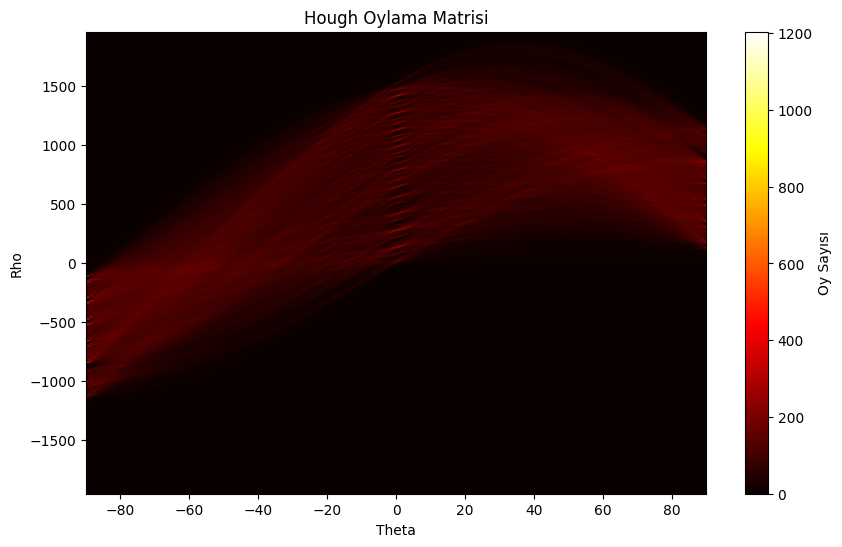

In [7]:
plt.figure(figsize=(10, 6))

plt.imshow(
    oylama,
    cmap="hot",
    aspect="auto",
    origin="lower",
    extent=[-90, 90, -max_rho, max_rho]
)

plt.title("Hough Oylama Matrisi")
plt.xlabel("Theta")
plt.ylabel("Rho")
plt.colorbar(label="Oy Sayısı")

plt.savefig("oylama_matrisi.png", dpi=200)
plt.show()

In [8]:
esik = max(25, int(oylama.max() * 0.45))

adaylar = np.argwhere(oylama >= esik)

adaylar = sorted(
    adaylar,
    key=lambda p: oylama[p[0], p[1]],
    reverse=True
)

secilenler = []

for r, t in adaylar:

    yakin = False

    for r2, t2 in secilenler:
        if abs(r-r2) <= 12 and abs(t-t2) <= 8:
            yakin = True
            break

    if not yakin:
        secilenler.append((r, t))

    if len(secilenler) >= 20:
        break

print("Eşik değeri:", esik)
print("Bulunan doğru sayısı:", len(secilenler))

Eşik değeri: 541
Bulunan doğru sayısı: 20


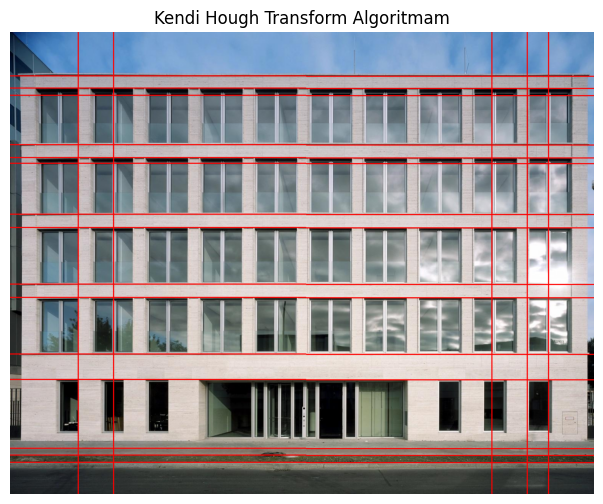

True

In [9]:
sonuc = resim.copy()

uzunluk = 2 * max_rho

for r, t in secilenler:

    rho = r - max_rho

    a = cos_tablosu[t]
    b = sin_tablosu[t]

    x0 = a * rho
    y0 = b * rho

    x1 = int(x0 + uzunluk * (-b))
    y1 = int(y0 + uzunluk * a)

    x2 = int(x0 - uzunluk * (-b))
    y2 = int(y0 - uzunluk * a)

    cv2.line(
        sonuc,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        2
    )

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Kendi Hough Transform Algoritmam")
plt.axis("off")
plt.show()

cv2.imwrite("hough_sonuc.png", sonuc)